In [ ]:
!pip install split-folders

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import keras
import splitfolders
from keras.models import Sequential
from keras.layers import Conv2D,Flatten,Dense,MaxPooling2D
from keras.preprocessing.image import ImageDataGenerator

In [ ]:
path='/content/drive/MyDrive/dataset'
splitfolders.ratio(path,output='/content/drive/MyDrive/data_output',seed=42,ratio=(0.8,0.1,0.1))

Copying files: 428 files [00:07, 56.59 files/s]


In [ ]:
datagen=ImageDataGenerator(fill_mode='nearest',
                           zoom_range=0.2,
                           horizontal_flip=True,
                           vertical_flip=True,
                           brightness_range=[0.4,1.5])
x_train_dataset = datagen.flow_from_directory('/content/drive/MyDrive/data_output/train',
                                              batch_size=100,
                                              shuffle=True,
                                              target_size=(256,256))
x_train,y_train=x_train_dataset.next()

Found 342 images belonging to 3 classes.


In [ ]:
x_test_dataset=datagen.flow_from_directory('/content/drive/MyDrive/data_output/test',
                                           batch_size=100,
                                           shuffle=True,
                                           target_size=(256,256))
x_test,y_test=x_test_dataset.next()

Found 44 images belonging to 3 classes.


In [ ]:
x_val_dataset=datagen.flow_from_directory('/content/drive/MyDrive/data_output/val',
                                          batch_size=100,
                                          shuffle=True,
                                          target_size=(256,256))
x_val,y_val=x_val_dataset.next()

Found 42 images belonging to 3 classes.


In [ ]:
y_test=y_test.astype('int32')
y_train=y_train.astype('int32')
y_val=y_val.astype('int32')

In [ ]:
print("x_train_shape:",x_train.shape)
print("y_train_shape:",y_train.shape)
print("x_test_shape:",x_test.shape)
print("y_test_shape:",y_test.shape)

x_train_shape: (100, 256, 256, 3)
y_train_shape: (100, 3)
x_test_shape: (44, 256, 256, 3)
y_test_shape: (44, 3)


In [31]:

model = Sequential()
model.add(Conv2D(32,kernel_size=(3, 3), activation='relu', input_shape=(256,256,3)))
model.add(Flatten())
model.add(Dense(128,activation='relu'))
model.add(Dense(130,activation='relu'))
model.add(Dense(175,activation='relu'))
model.add(Dense(200, activation='relu'))
model.add(Dense(3, activation = 'softmax'))


In [32]:
model.compile(optimizer = 'adam',
              loss = 'categorical_crossentropy',
              metrics=['accuracy'])

In [33]:
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 254, 254, 32)      896       
                                                                 
 flatten_3 (Flatten)         (None, 2064512)           0         
                                                                 
 dense_6 (Dense)             (None, 128)               264257664 
                                                                 
 dense_7 (Dense)             (None, 130)               16770     
                                                                 
 dense_8 (Dense)             (None, 175)               22925     
                                                                 
 dense_9 (Dense)             (None, 200)               35200     
                                                                 
 dense_10 (Dense)            (None, 3)                

In [34]:
model.fit(x_train,y_train,epochs=10,validation_split=0.20)

Epoch 1/10
3/3 [==============================] - 19s 4s/step - loss: 9950.4844 - accuracy: 0.3000 - val_loss: 10123.7363 - val_accuracy: 0.4500
Epoch 2/10
3/3 [==============================] - 12s 4s/step - loss: 9434.9941 - accuracy: 0.4750 - val_loss: 8269.2129 - val_accuracy: 0.4500
Epoch 3/10
3/3 [==============================] - 13s 4s/step - loss: 11010.4551 - accuracy: 0.3125 - val_loss: 7087.4648 - val_accuracy: 0.4500
Epoch 4/10
3/3 [==============================] - 16s 5s/step - loss: 4572.6963 - accuracy: 0.4250 - val_loss: 5048.6333 - val_accuracy: 0.2500
Epoch 5/10
3/3 [==============================] - 13s 4s/step - loss: 3418.4871 - accuracy: 0.3875 - val_loss: 4070.4517 - val_accuracy: 0.3000
Epoch 6/10
3/3 [==============================] - 14s 4s/step - loss: 2161.3787 - accuracy: 0.3125 - val_loss: 844.4113 - val_accuracy: 0.4500
Epoch 7/10
3/3 [==============================] - 14s 5s/step - loss: 859.4935 - accuracy: 0.4625 - val_loss: 1189.2976 - val_accuracy:

In [35]:
test=model.evaluate(x_test,y_test)
print("Test Accuracy:",test[1])
print("Loss:",test[0])

2/2 [==============================] - 1s 382ms/step - loss: 122.6330 - accuracy: 0.4773
Test Accuracy: 0.47727271914482117
Loss: 122.6330337524414


In [36]:
train=model.evaluate(x_train,y_train)
print("Train Accuracy:",train[1])
print("Loss:",train[0])

4/4 [==============================] - 5s 1s/step - loss: 83.4474 - accuracy: 0.6700
Train Accuracy: 0.6700000166893005
Loss: 83.44737243652344


In [37]:
val=model.evaluate(x_val,y_val)
print("Val Accuracy:",val[1])
print("Loss:",val[0])

2/2 [==============================] - 1s 356ms/step - loss: 95.4631 - accuracy: 0.5714
Val Accuracy: 0.5714285969734192
Loss: 95.46309661865234


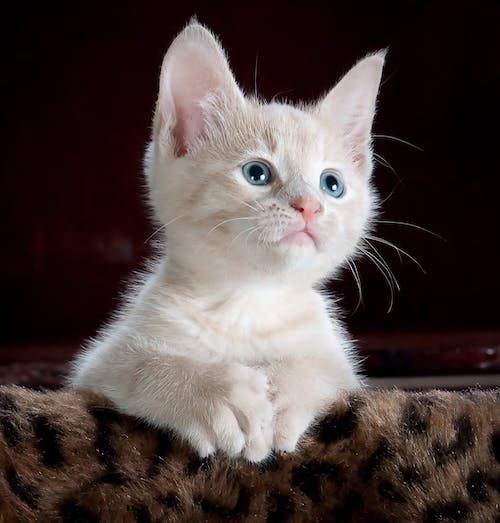

Image Shape: (523, 500, 3)


In [38]:
#prediction
import cv2
from google.colab.patches import cv2_imshow
img=cv2.imread('/content/drive/MyDrive/ct.jpeg')
cv2_imshow(img)
print("Image Shape:",img.shape)

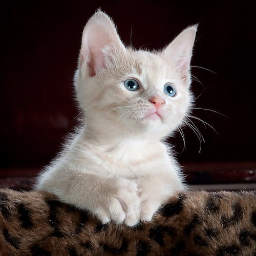

Image Shape: (256, 256, 3)


In [39]:
#Resize
re=cv2.resize(img,(256,256))
#reshape
im=re.reshape(-1,256,256,3)
cv2_imshow(re)
print("Image Shape:",re.shape)

In [40]:
p=model.predict(im)

1/1 [==============================] - 0s 238ms/step


In [41]:
print(np.argmax(p))

2


Class Labels   
Cats=0
dogs=1
tiger=2

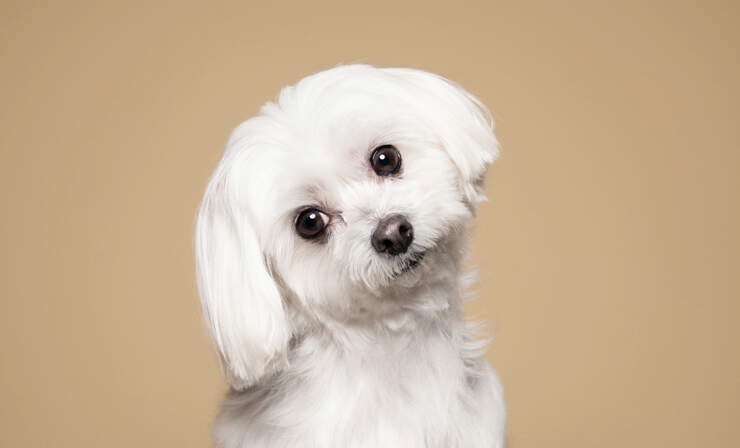

Image Shape: (448, 740, 3)


In [42]:
#prediction
import cv2
from google.colab.patches import cv2_imshow
img=cv2.imread('/content/drive/MyDrive/dg.jpg')
cv2_imshow(img)
print("Image Shape:",img.shape)

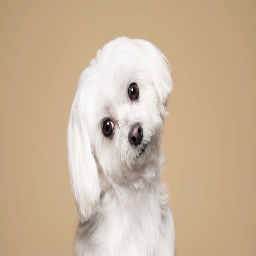

Image Shape: (256, 256, 3)


In [43]:
#Resize
re=cv2.resize(img,(256,256))
#reshape
im=re.reshape(-1,256,256,3)
cv2_imshow(re)
print("Image Shape:",re.shape)

In [44]:
p=model.predict(im)

1/1 [==============================] - 0s 180ms/step


In [45]:
print(np.argmax(p))

0


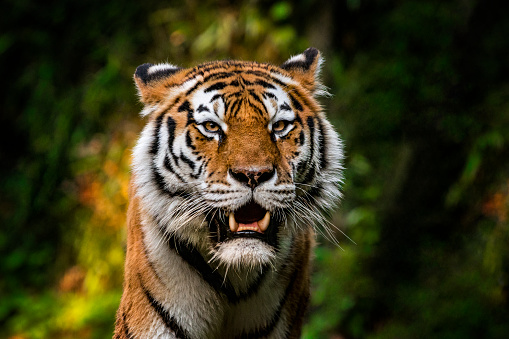

Image Shape: (339, 509, 3)


In [46]:
#prediction
import cv2
from google.colab.patches import cv2_imshow
img=cv2.imread('/content/drive/MyDrive/tiger.jpg')
cv2_imshow(img)
print("Image Shape:",img.shape)

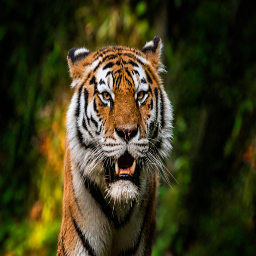

Image Shape: (256, 256, 3)


In [47]:
#Resize
re=cv2.resize(img,(256,256))
#reshape
im=re.reshape(-1,256,256,3)
cv2_imshow(re)
print("Image Shape:",re.shape)

In [48]:
p=model.predict(im)

1/1 [==============================] - 0s 172ms/step


In [49]:
print(np.argmax(p))

2
